# PARCIAL #3 - PDI
- Julián Cruz
- Sebastian Montaño
- Alejandro Quintero

**Profesor: Nicolas Llanos Neuta**

**Universidad Autonoma de Occidente**

# Enlaces del entregable, versiones y semillas

| Recurso | Ubicación en Drive | Enlace |
|---|---|---|
| Dataset del Punto 1 (imágenes, máscaras y particiones) | `PDI_Parcial3_dataset/` → `images/`, `masks/`, `splits.csv` | https://drive.google.com/drive/folders/1-824ST5Jt7wAro3Q1l0_a41ncL5zK0OM?usp=sharing|
| Pesos entrenados de la U-Net (Punto 1) | `PDI_Parcial3_dataset/unet_resnet18_imagenet.pth` (modelo final: ImageNet, aumento normal), `unet_resnet18_imagenet_augfuerte.pth` (experimento del Paso 6) y `unet_resnet18_sin_preentrenamiento_augnormal.pth` (Paso 8) | https://drive.google.com/drive/folders/1-824ST5Jt7wAro3Q1l0_a41ncL5zK0OM?usp=sharing |
| Pesos entrenados de la LoRA (Punto 2) | `PDI_Parcial3/lora_sks/pytorch_lora_weights.safetensors` (más `checkpoint-200/400/600/800`) | https://drive.google.com/drive/folders/149tvcRQDYsS_t5ftw35_QeCEze38AYlS?usp=sharing |

**Versiones usadas:** PyTorch 2.14.1+cu130 (CUDA 13.0), diffusers 0.43.0, transformers 5.23.0, peft 0.21.3, accelerate 1.15.0, segmentation-models-pytorch 0.6.0, Albumentations 2.0.8, OpenCV 4.14.0. GPU: Tesla T4.

**Semillas:** `SEED = 42` fijada al inicio de cada punto (random, NumPy, PyTorch y cuDNN determinista); en el Punto 2 las imágenes de evaluación usan las semillas 0, 1, 2 y 3.

**Nota sobre reproducibilidad:** el aumento de datos aleatorio y los procesos del DataLoader hacen que dos entrenamientos con la misma semilla no den resultados idénticos (al repetir el entrenamiento con aumento fuerte, la mejor pérdida de validación fue 0.0976, 0.1044 y 0.1142). Por eso se entregan los pesos: la celda "Reproducir las figuras sin reentrenar" (al final del Punto 1) y el Paso 5 del Punto 2 los cargan desde Drive.

# 1. Segmentación semántica con U-Net sobre propio dataset


## Paso 1. Leer el blog de referencia

**¿Qué entra a la red y qué sale? Indique la forma de los tensores de imagen y de máscara.**

  A la red entra una imagen RGB de 128x128 ya normalizada con la media y la desviación estándar de ImageNet, con forma [B, 3, 128, 128], donde B es el batch size, es decir, cuántas imágenes se procesan juntas a la vez.

  La máscara objetivo es la imagen que generamos rellenando con cv2.fillPoly los polígonos dibujados en makesense. Tiene forma [B, 1, 128, 128], con valores 0 (fondo) y 1 (persona). Como tenemos la respuesta correcta para cada imagen, es aprendizaje supervisado.

  De la red sale un mapa de 1 canal del mismo tamaño, [B, 1, 128, 128]. Es un solo canal porque es segmentación de una sola clase: persona vs fondo. La última capa entrega un logit por píxel, que es un número real cualquiera. Para interpretarlo aplicamos la sigmoide, que lo convierte en una probabilidad entre 0 y 1, y luego un umbral de 0.5: si la probabilidad es mayor a 0.5 el píxel se asigna a persona (1), y si no, a fondo (0). La máscara binaria resultante se compara con la máscara real usando el Dice.

  La imagen se redimensiona a 128x128 en el Pipeline 1 y se normaliza en el Pipeline 2, al cargarla en el Dataset. La máscara solo se redimensiona, no se normaliza.

  (esto para nuestro caso, ya que el blog trabaja con un dataset de carros)


**¿Qué hace cada uno de los cuatro pipelines del blog?**

  El **Pipeline 1** para el caso del blog es de preprocesamiento, Convierte las máscaras de .gif a .png con PIL, tambien redimensiona las imagenes y mascaras que usamos en la red de 1280×1918 a 128×128, adicionalmente, carga train_masks.csv solo para tener los nombres de archivo y por ultimo define media y desviación de ImageNet, porque el encoder ResNet18 fue preentrenado con esas estadísticas.

  El **Pipeline 2** hace uso de get_transform(phase) para aplicar HorizontalFlip(p=0.5) solo en train (foto y mascara se voltean juntos) no importa si en val no se hace ya que es un conjunto de fotos distinas. Lo anterior es una estrategia de data augmentation. En ambas fases aplica Normalize y ToTensor.

  CarDataset lee imagen y máscara por índice y les aplica la transformación juntas. Entrega [3,128,128] y [1,128,128], y finalmente, CarDataloader divide los nombres en train/val con train_test_split (80/20, random_state=69) y crea el DataLoader de cada fase.

**El pipeline 3: Scores**

  Define cómo se mide el desempeño con el Dice score: binariza la predicción (logit > 0, que equivale a sigmoide > 0.5) y calcula 2·intersección / suma entre la máscara predicha y la real. Se calcula por lote y al final de cada época se promedia. En el blog el Dice se usa solo como métrica; la pérdida con la que se entrena la red es BCEWithLogitsLoss (se define dentro del Trainer), porque el Dice binarizado no es derivable y no sirve para corregir los pesos.

**El pipeline 4**

  La clase Trainer ejecuta el entrenamiento. En cada época recorre la fase train y luego la fase val. En train hace el forward, calcula la pérdida (BCE), calcula los gradientes con backward y actualiza los pesos con Adam; acumula gradientes durante 4 lotes antes de actualizar. En val solo evalúa, sin gradientes ni cambio de pesos. Registra la pérdida y el Dice de cada fase, ajusta el learning rate con ReduceLROnPlateau y guarda el modelo cuando mejora la pérdida de validación.

**¿Qué es una U-Net y qué papel cumplen el encoder, el decoder y las conexiones de salto?**

Una U-Net es una red convolucional diseñada para segmentación (se llama así por la forma de "U" de su diagrama). Recibe una imagen y entrega un mapa de la misma resolución en el que cada píxel queda clasificado.

- **Encoder (brazo descendente):** convoluciones y max pooling que van reduciendo la resolución mientras aumentan los canales. Aprende **qué hay** en la imagen, con rasgos cada vez más abstractos. En nuestro modelo es una ResNet18 preentrenada en ImageNet.
- **Decoder (brazo ascendente):** sube la resolución (upsampling / convoluciones transpuestas) hasta el tamaño original. Aprende **dónde está** el objeto.
- **Conexiones de salto (skip connections):** unen cada nivel del encoder con el nivel del decoder de igual resolución y concatenan sus mapas de características. Al bajar la resolución el encoder pierde bordes y detalles finos; las conexiones se los devuelven al decoder, y por eso la máscara final tiene contornos precisos y no solo una mancha aproximada.

**¿Por qué el blog mide con Dice y no solo con el porcentaje de píxeles acertados?**

Porque la exactitud de píxeles se infla con el fondo: si el objeto ocupa poco de la imagen, un modelo que prediga "todo fondo" acierta casi todos los píxeles sin segmentar nada. El Dice, 2·|A∩B| / (|A|+|B|), mide solo el solapamiento entre la máscara predicha y la real; no premia acertar el fondo y vale 0 si el modelo no encuentra el objeto. (En el blog el Dice se usa solo para medir; la pérdida de entrenamiento es BCE.) En nuestro caso lo comprobamos con datos reales en el Paso 5.

## Configuración: librerías, semillas, versiones y rutas

In [ ]:
#CELDA 1 Librerías, semillas y versiones
!pip -q install segmentation-models-pytorch albumentations

import os, json, random, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

print("PyTorch:", torch.__version__)
print("Albumentations:", A.__version__)
print("smp:", smp.__version__)
print("OpenCV:", cv2.__version__)
print("GPU:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Albumentations: 2.0.8
smp: 0.6.0
OpenCV: 4.14.0
GPU: True


In [ ]:
#CELDA 2 Drive y rutas
from google.colab import drive
drive.mount('/content/drive')

# Entrada: carpeta compartida (vía acceso directo en Mi unidad), solo lectura
BASE     = Path('/content/drive/MyDrive/PDI_Parcial3')
SRC_IMG  = BASE / 'Imagenes_Punto1'          # fotos originales (80)
JSON_DIR = BASE / 'makesense.ai'             # Personas_Parte1.json y Parte2.json

# Salida: carpeta propia en Mi unidad
OUT      = Path('/content/drive/MyDrive/PDI_Parcial3_dataset')
IMG_DIR  = OUT / 'images'
MSK_DIR  = OUT / 'masks'
IMG_DIR.mkdir(parents=True, exist_ok=True)
MSK_DIR.mkdir(parents=True, exist_ok=True)

# Verificación de que las rutas existen
for nombre, ruta in [('BASE', BASE), ('SRC_IMG', SRC_IMG), ('JSON_DIR', JSON_DIR)]:
    print(f"{nombre}: {'OK' if ruta.exists() else 'NO ENCONTRADA'} -> {ruta}")

print(len(list(SRC_IMG.glob('*'))), "archivos en", SRC_IMG)
print([p.name for p in JSON_DIR.glob('*.json')])

Mounted at /content/drive
BASE: OK -> /content/drive/MyDrive/PDI_Parcial3
SRC_IMG: OK -> /content/drive/MyDrive/PDI_Parcial3/Imagenes_Punto1
JSON_DIR: OK -> /content/drive/MyDrive/PDI_Parcial3/makesense.ai
80 archivos en /content/drive/MyDrive/PDI_Parcial3/Imagenes_Punto1
['Personas_Parte2.json', 'Personas_Parte1.json']


## Paso 2. Elegir el objeto de nuestro propio dataset

**Objeto elegido: persona** (una sola clase: persona vs fondo). Aparece claramente en todas las fotos y tiene bordes bastante definidos, salvo el cabello (largo y rizado en varias fotos), que es lo más difícil de etiquetar y se tendrá en cuenta en el análisis.

**Dataset:** 80 fotos propias etiquetadas, tomadas en interiores y exteriores (salones, pasillos, casas, jardín), variando fondo, distancia, ángulo, pose e iluminación y evitando ráfagas. Además se apartaron **5 fotos extra sin etiquetar** (carpeta `Imagenes_Validacion_Punto1`), que no participan ni en el entrenamiento ni en la validación y se usan solo en el Paso 7.

## Paso 3. Etiquetar las máscaras

Las 80 fotos se etiquetaron en makesense.ai con polígonos (etiqueta "persona") y se exportaron en formato COCO JSON, en dos partes. En el notebook se unen los JSON, se verifican y se convierten en máscaras PNG con `cv2.fillPoly`.

In [ ]:
#CELDA 3 Leer los JSON COCO y unirlos por nombre de archivo
def cargar_coco(path):
    with open(path) as f:
        coco = json.load(f)
    id2img = {im['id']: im for im in coco['images']}
    ann = {im['file_name']: {'w': im['width'], 'h': im['height'], 'polys': []}
           for im in coco['images']}
    for a in coco['annotations']:
        nombre = id2img[a['image_id']]['file_name']
        for poly in a['segmentation']:                    # lista de polígonos
            pts = np.array(poly, dtype=np.float32).reshape(-1, 2)
            ann[nombre]['polys'].append(pts)
    return ann

ann1 = cargar_coco(JSON_DIR / 'Personas_Parte1.json')
ann2 = cargar_coco(JSON_DIR / 'Personas_Parte2.json')

duplicadas = set(ann1) & set(ann2)
print("Parte1:", len(ann1), "| Parte2:", len(ann2), "| duplicadas:", len(duplicadas))

ann = {**ann1, **ann2}
print("Total imágenes anotadas:", len(ann))

Parte1: 40 | Parte2: 40 | duplicadas: 0
Total imágenes anotadas: 80


In [ ]:
#CELDA 4 Verificaciones
archivos = {p.name for p in SRC_IMG.glob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png')}

sin_archivo = [n for n in ann if n not in archivos]
sin_etiqueta = [n for n in archivos if n not in ann]
sin_poligono = [n for n, d in ann.items() if len(d['polys']) == 0]
multi = {n: len(d['polys']) for n, d in ann.items() if len(d['polys']) > 1}

print("En el JSON pero no en la carpeta:", sin_archivo)
print("En la carpeta pero no en el JSON:", sin_etiqueta)
print("Sin polígonos:", sin_poligono)
print("Con más de un polígono:", multi)

# Tamaño real vs tamaño del JSON (detecta problemas de rotación EXIF)
desajuste = []
for n, d in ann.items():
    if n in archivos:
        h, w = cv2.imread(str(SRC_IMG / n)).shape[:2]
        if (w, h) != (d['w'], d['h']):
            desajuste.append((n, (w, h), (d['w'], d['h'])))
print("Imágenes con tamaño distinto al del JSON:", desajuste)

En el JSON pero no en la carpeta: []
En la carpeta pero no en el JSON: []
Sin polígonos: []
Con más de un polígono: {}
Imágenes con tamaño distinto al del JSON: []


In [ ]:
#CELDA 5 Generar máscaras con cv2.fillPoly
for nombre, d in tqdm(ann.items()):
    img = cv2.imread(str(SRC_IMG / nombre))          # aplica la orientación EXIF
    h, w = img.shape[:2]

    mask = np.zeros((h, w), dtype=np.uint8)
    polys = [np.round(p).astype(np.int32) for p in d['polys']]
    cv2.fillPoly(mask, polys, 255)

    stem = Path(nombre).stem
    cv2.imwrite(str(IMG_DIR / f'{stem}.jpg'), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    cv2.imwrite(str(MSK_DIR / f'{stem}.png'), mask)

print("Imágenes guardadas:", len(list(IMG_DIR.glob('*'))))
print("Máscaras guardadas:", len(list(MSK_DIR.glob('*'))))

  0%|          | 0/80 [00:00<?, ?it/s]

Imágenes guardadas: 80
Máscaras guardadas: 80


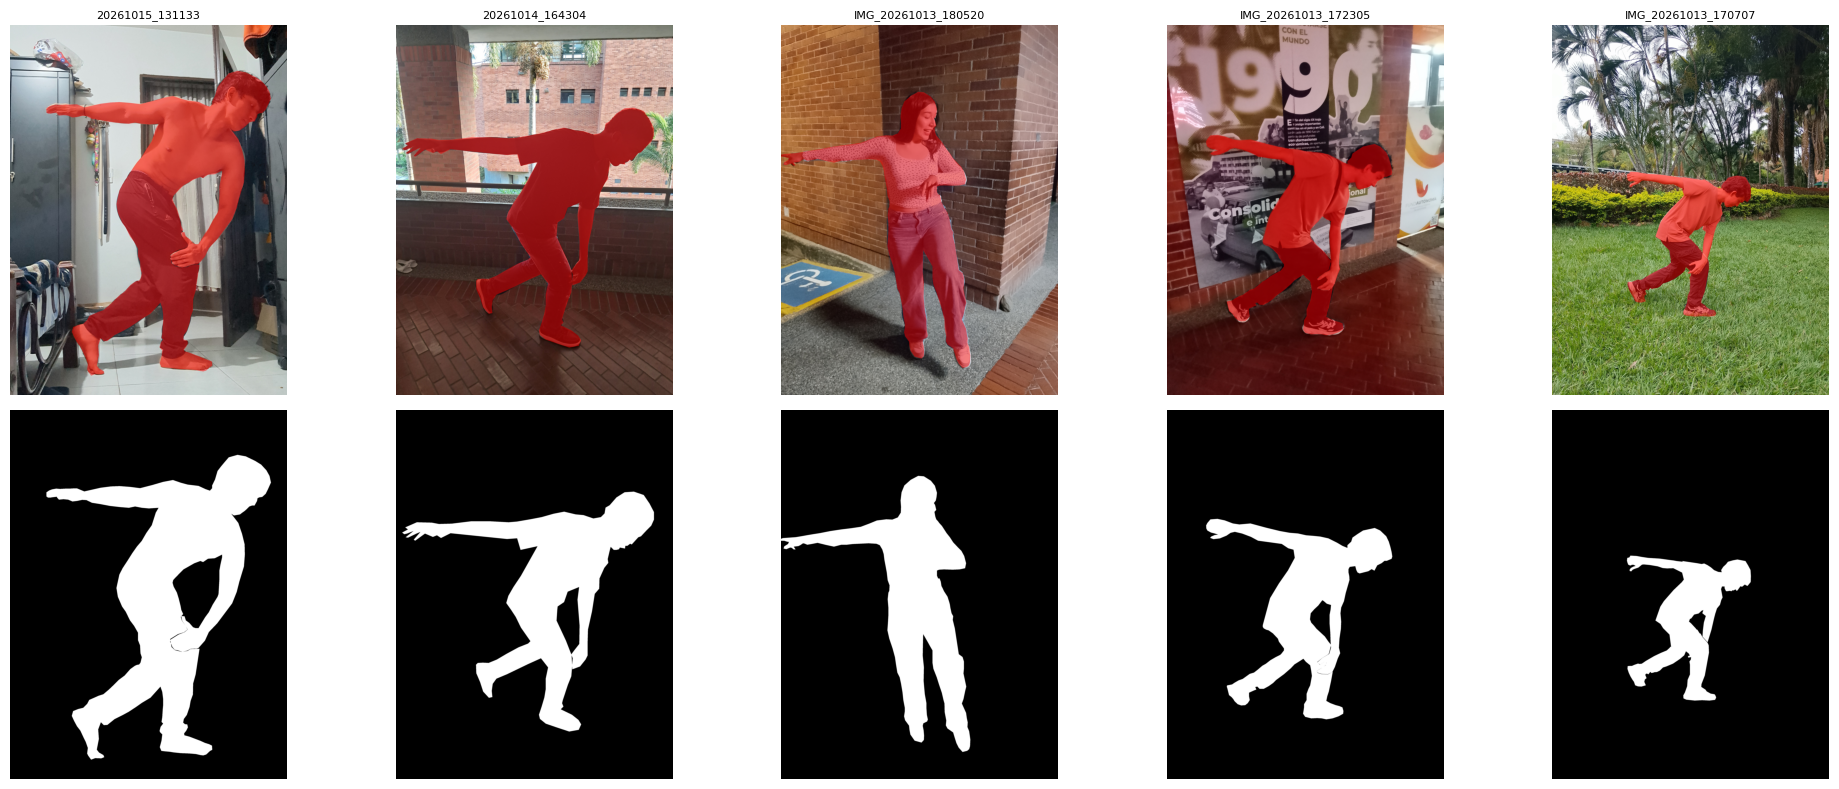

In [ ]:
#CELDA 6 Mostrar 5 imágenes con la máscara superpuesta

stems = sorted(p.stem for p in MSK_DIR.glob('*.png'))
muestra = random.sample(stems, 5)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, s in enumerate(muestra):
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / f'{s}.jpg')), cv2.COLOR_BGR2RGB)
    msk = cv2.imread(str(MSK_DIR / f'{s}.png'), cv2.IMREAD_GRAYSCALE)

    overlay = img.copy()
    overlay[msk > 0] = (0.5 * overlay[msk > 0] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)

    axes[0, i].imshow(overlay); axes[0, i].set_title(s, fontsize=8); axes[0, i].axis('off')
    axes[1, i].imshow(msk, cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel("Superposición"); axes[1, 0].set_ylabel("Máscara")
plt.tight_layout(); plt.show()

**Análisis del Paso 3.** Cada JSON se leyó por separado y se unieron por nombre de archivo, porque los `id` internos se repiten entre exportaciones. Las verificaciones salieron limpias: no hay archivos faltantes ni sobrantes, ninguna imagen quedó sin polígono, cada imagen tiene exactamente un polígono (una persona por foto) y el tamaño real de cada foto coincide con el del JSON, así que las máscaras no quedan rotadas. Cada polígono se rasterizó con `cv2.fillPoly` (blanco = persona, negro = fondo) en una máscara del tamaño original, con el mismo nombre que la foto, en `images/` y `masks/`. En las superposiciones las máscaras siguen el contorno de la persona. Limitación: un polígono es una aproximación hecha a mano; los bordes más difíciles de etiquetar son el cabello y las manos, donde puede haber errores de unos pocos píxeles.

## Paso 4. Preparar los datos (pipelines 1 y 2 del blog)

In [ ]:
#Celda 7: Pipeline 1, redimensionar en paralelo
from concurrent.futures import ThreadPoolExecutor

IMG_SIZE = 128
LOCAL = Path('/content/data_128')
L_IMG, L_MSK = LOCAL / 'images', LOCAL / 'masks'
L_IMG.mkdir(parents=True, exist_ok=True)
L_MSK.mkdir(parents=True, exist_ok=True)

def redimensionar(stem):
    img = cv2.imread(str(IMG_DIR / f'{stem}.jpg'))
    msk = cv2.imread(str(MSK_DIR / f'{stem}.png'), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    msk = cv2.resize(msk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    cv2.imwrite(str(L_IMG / f'{stem}.png'), img)
    cv2.imwrite(str(L_MSK / f'{stem}.png'), msk)

stems = sorted(p.stem for p in MSK_DIR.glob('*.png'))
with ThreadPoolExecutor(8) as ex:
    list(tqdm(ex.map(redimensionar, stems), total=len(stems)))

print(len(list(L_IMG.glob('*.png'))), "imágenes y", len(list(L_MSK.glob('*.png'))), "máscaras de", IMG_SIZE, "x", IMG_SIZE)

  0%|          | 0/80 [00:00<?, ?it/s]

80 imágenes y 80 máscaras de 128 x 128


In [ ]:
#Celda 8 Split train / val / test (70/15/15)
trainval, test = train_test_split(stems, test_size=12, random_state=SEED)
train, val     = train_test_split(trainval, test_size=12, random_state=SEED)

df = pd.DataFrame(
    [(s, 'train') for s in train] + [(s, 'val') for s in val] + [(s, 'test') for s in test],
    columns=['img', 'split']
)
df.to_csv(OUT / 'splits.csv', index=False)

print(df['split'].value_counts())

split
train    56
val      12
test     12
Name: count, dtype: int64


In [ ]:
#Celda 9 Porcentaje de la imagen que ocupa el persona
def pct_objeto(stem):
    m = cv2.imread(str(L_MSK / f'{stem}.png'), cv2.IMREAD_GRAYSCALE)
    return (m > 127).mean() * 100

df['pct_objeto'] = df['img'].apply(pct_objeto)

print(df.groupby('split')['pct_objeto'].agg(['count', 'mean', 'min', 'max']).round(2))
print(f"\nPromedio global: {df['pct_objeto'].mean():.2f}% de la imagen")

       count   mean   min    max
split                           
test      12  13.63  6.68  21.07
train     56  17.44  9.28  30.33
val       12  15.43  9.89  24.02

Promedio global: 16.56% de la imagen


In [ ]:
#Celda 10: Transformaciones y Dataset

mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

def get_transform(phase):
    t = []
    if phase == 'train':
        t += [
            A.HorizontalFlip(p=0.5),
            A.Rotate(limit=15, p=0.5, border_mode=cv2.BORDER_CONSTANT),
            A.RandomBrightnessContrast(p=0.5),
        ]
    t += [A.Normalize(mean=mean, std=std), ToTensorV2()]
    return A.Compose(t)

class PersonasDataset(torch.utils.data.Dataset):
    def __init__(self, df, phase):
        self.names = df[df['split'] == phase]['img'].tolist()
        self.transform = get_transform(phase)

    def __getitem__(self, idx):
        s = self.names[idx]
        img = cv2.cvtColor(cv2.imread(str(L_IMG / f'{s}.png')), cv2.COLOR_BGR2RGB)
        msk = cv2.imread(str(L_MSK / f'{s}.png'), cv2.IMREAD_GRAYSCALE)
        msk = (msk > 127).astype(np.uint8)                 # 0 / 1

        aug = self.transform(image=img, mask=msk)           # misma transformación a ambas
        return aug['image'], aug['mask'].float().unsqueeze(0)   # [3,H,W], [1,H,W]

    def __len__(self):
        return len(self.names)

def get_loader(phase, batch_size=8):
    ds = PersonasDataset(df, phase)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=(phase == 'train'),
                                       num_workers=2, pin_memory=True)

loaders = {p: get_loader(p) for p in ['train', 'val', 'test']}

In [ ]:
#Celda 11: Verificar formas y valores de un lote

imgs, msks = next(iter(loaders['train']))
print("imágenes:", imgs.shape, imgs.dtype, f"| rango [{imgs.min():.2f}, {imgs.max():.2f}]")
print("máscaras:", msks.shape, msks.dtype, "| valores únicos:", msks.unique().tolist())

imágenes: torch.Size([8, 3, 128, 128]) torch.float32 | rango [-2.12, 2.64]
máscaras: torch.Size([8, 1, 128, 128]) torch.float32 | valores únicos: [0.0, 1.0]


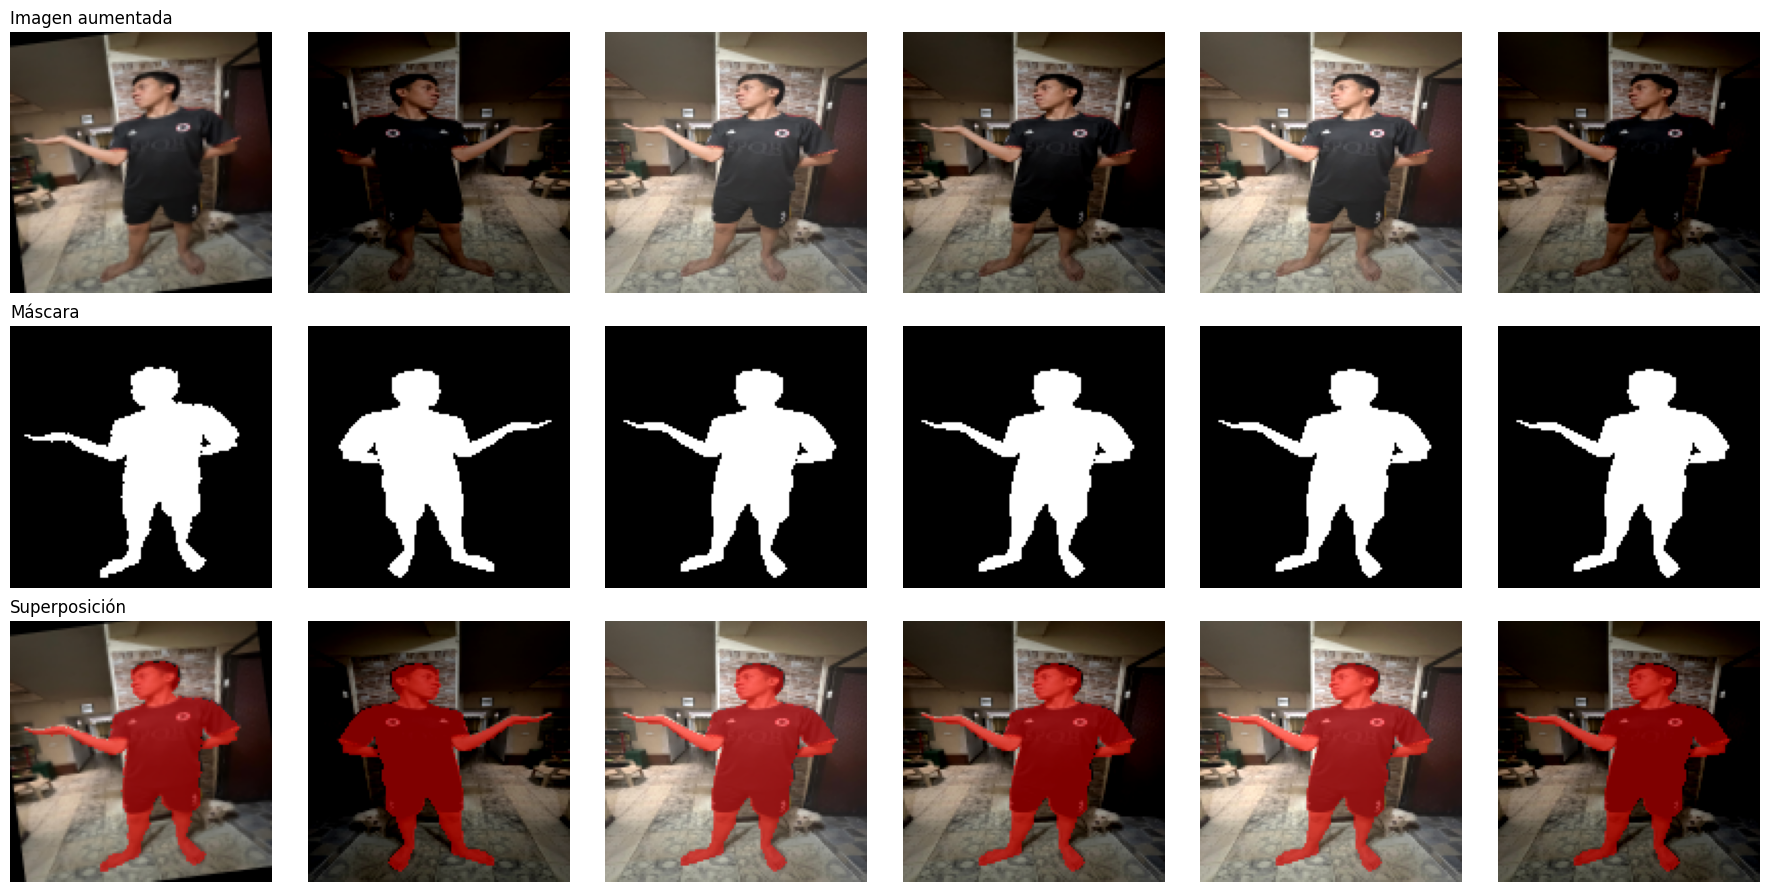

In [ ]:
#Celda 12: Mostrar el aumento (imagen y máscara se transforman juntas)
def desnormalizar(t):
    x = t.permute(1, 2, 0).numpy() * np.array(std) + np.array(mean)
    return np.clip(x, 0, 1)

ds_train = PersonasDataset(df, 'train')
idx = 0
n = 6

fig, axes = plt.subplots(3, n, figsize=(3 * n, 9))
for j in range(n):
    img_t, msk_t = ds_train[idx]
    img = desnormalizar(img_t)
    msk = msk_t[0].numpy()

    overlay = img.copy()
    overlay[msk > 0] = 0.5 * overlay[msk > 0] + 0.5 * np.array([1, 0, 0])

    axes[0, j].imshow(img);                axes[0, j].axis('off')
    axes[1, j].imshow(msk, cmap='gray');   axes[1, j].axis('off')
    axes[2, j].imshow(overlay);            axes[2, j].axis('off')
axes[0, 0].set_title("Imagen aumentada", loc='left')
axes[1, 0].set_title("Máscara", loc='left')
axes[2, 0].set_title("Superposición", loc='left')
plt.tight_layout(); plt.show()

**Análisis del Paso 4.** Imágenes y máscaras se redimensionaron a 128×128 (`INTER_AREA` para las imágenes y `INTER_NEAREST` para las máscaras, así siguen siendo binarias), en paralelo con `ThreadPoolExecutor` como en el Pipeline 1, y se guardaron copias locales para no leer fotos grandes desde Drive en cada época. La partición con semilla fija es **56 train / 12 val / 12 test** (70/15/15) y quedó guardada en `splits.csv`. En promedio la persona ocupa **16.56 %** de la imagen (train 17.44 %, val 15.43 %, test 13.63 %; rango de 6.68 % a 30.33 %), por lo que el fondo es más del 80 % de los píxeles. Un lote tiene forma `[8, 3, 128, 128]` para las imágenes (valores normalizados entre −2.12 y 2.64) y `[8, 1, 128, 128]` para las máscaras (valores únicos 0 y 1). El aumento se aplica solo en train: volteo horizontal, rotación de hasta 15° y brillo/contraste. La figura muestra la misma foto con seis sorteos distintos y la máscara se voltea y rota junto con la imagen, así que sigue alineada; el brillo solo afecta a la imagen y Normalize no toca la máscara. Limitación: las fotos son verticales y al llevarlas a 128×128 se deforman; se hace igual en todas las particiones. En el Paso 6 se prueba además un aumento más fuerte.

## Paso 5. Modelo y función de pérdida (pipeline 3 del blog)

In [ ]:
#Celda 13: Crear el modelo e imprimir la arquitectura
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = smp.Unet("resnet18", encoder_weights="imagenet", classes=1, activation=None).to(device)
print("Dispositivo:", device)
print(model)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Dispositivo: cuda
Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNor

In [ ]:
#Celda 14: Número de parámetros, por componente

def contar(m):
    return sum(p.numel() for p in m.parameters())

total = contar(model)
entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total de parámetros:      {total:,}")
print(f"Entrenables:              {entrenables:,}")
print(f"Encoder (ResNet18):       {contar(model.encoder):,}  ({contar(model.encoder)/total:.1%})")
print(f"Decoder (U-Net):          {contar(model.decoder):,}  ({contar(model.decoder)/total:.1%})")
print(f"Cabeza de segmentación:   {contar(model.segmentation_head):,}  ({contar(model.segmentation_head)/total:.1%})")

Total de parámetros:      14,328,209
Entrenables:              14,328,209
Encoder (ResNet18):       11,176,512  (78.0%)
Decoder (U-Net):          3,151,552  (22.0%)
Cabeza de segmentación:   145  (0.0%)


In [ ]:
#Celda 15: Ubicar encoder, decoder y skip connections con tensores reales
formas = {}

def espiar(nombre):
    def hook(modulo, entrada, salida):
        if isinstance(salida, (list, tuple)):
            formas[nombre] = [tuple(t.shape) for t in salida]
        else:
            formas[nombre] = tuple(salida.shape)
    return hook

hooks = [
    model.encoder.register_forward_hook(espiar('encoder')),
    model.decoder.register_forward_hook(espiar('decoder')),
    model.segmentation_head.register_forward_hook(espiar('cabeza')),
]

model.eval()
with torch.no_grad():
    salida = model(torch.randn(4, 3, 128, 128).to(device))

for h in hooks:
    h.remove()

print("ENTRADA            : (4, 3, 128, 128)")
print("ENCODER, mapas por etapa (candidatos a skip connections):")
for i, f in enumerate(formas['encoder']):
    print(f"   etapa {i}: {f}")
print("DECODER (salida)   :", formas['decoder'])
print("CABEZA 1x1 (logits):", formas['cabeza'])

ENTRADA            : (4, 3, 128, 128)
ENCODER, mapas por etapa (candidatos a skip connections):
   etapa 0: (4, 3, 128, 128)
   etapa 1: (4, 64, 64, 64)
   etapa 2: (4, 64, 32, 32)
   etapa 3: (4, 128, 16, 16)
   etapa 4: (4, 256, 8, 8)
   etapa 5: (4, 512, 4, 4)
DECODER (salida)   : (4, 16, 128, 128)
CABEZA 1x1 (logits): (4, 1, 128, 128)


In [ ]:
#Celda 16: Pérdida y métrica Dice del blog
criterion = nn.BCEWithLogitsLoss()

def dice_score(logits, targets, eps=1e-7):
    pred = (logits > 0).float()                       # logit > 0  <=>  sigmoide > 0.5
    return (2. * (pred * targets).sum() + eps) / ((pred + targets).sum() + eps)

# Prueba con un lote real y el modelo SIN entrenar
imgs, msks = next(iter(loaders['val']))
imgs, msks = imgs.to(device), msks.to(device)
model.eval()
with torch.no_grad():
    logits = model(imgs)
print("Pérdida BCE (sin entrenar):", round(criterion(logits, msks).item(), 4))
print("Dice (sin entrenar):       ", round(dice_score(logits, msks).item(), 4))

Pérdida BCE (sin entrenar): 0.6848
Dice (sin entrenar):        0.0366


In [ ]:
#Celda 17: Demostrar por qué no basta la exactitud de píxeles
masks = torch.stack([
    torch.from_numpy((cv2.imread(str(L_MSK / f'{s}.png'), cv2.IMREAD_GRAYSCALE) > 127).astype('float32'))
    for s in df[df['split'] == 'train']['img']
]).unsqueeze(1)                                       # [56, 1, 128, 128]

def exactitud(pred, real):
    return (pred == real).float().mean().item()

# Caso A: predecir todo fondo
logit_fondo = -torch.ones_like(masks)
pred_A = (logit_fondo > 0).float()

# Caso B: marcar solo la mitad superior de la persona
pred_B = masks.clone()
pred_B[:, :, 64:, :] = 0
logit_B = torch.where(pred_B > 0, torch.ones_like(masks), -torch.ones_like(masks))

filas = [
    ("Perfecto (máscara real)", masks, torch.where(masks > 0, 1., -1.)),
    ("A: todo fondo", pred_A, logit_fondo),
    ("B: solo mitad superior", pred_B, logit_B),
]
print(f"{'Predicción':28s} {'Exactitud':>10s} {'Dice':>8s}")
for nombre, pred, logit in filas:
    print(f"{nombre:28s} {exactitud(pred, masks):10.4f} {dice_score(logit, masks).item():8.4f}")

Predicción                    Exactitud     Dice
Perfecto (máscara real)          1.0000   1.0000
A: todo fondo                    0.8256   0.0000
B: solo mitad superior           0.9131   0.6679


**Análisis de la arquitectura.** El modelo (`smp.Unet`, encoder ResNet18 con pesos de ImageNet, 1 canal de salida, sin activación) tiene **14,328,209 parámetros**, todos entrenables. El **encoder** concentra 11,176,512 (78.0 %) y reduce la entrada de 128×128 a 4×4 mientras sube los canales hasta 512. El **decoder** tiene 3,151,552 (22.0 %) y vuelve a subir la resolución hasta 128×128 con 16 canales. La **cabeza de segmentación** (145 parámetros: una convolución 3×3) entrega 1 canal de logits. Las **conexiones de salto** no aparecen como módulos con nombre: dentro del decoder se concatenan los mapas del encoder de igual resolución (256@8×8, 128@16×16, 64@32×32 y 64@64×64) con los que vienen subiendo. El mapa de 512@4×4 es el cuello de botella con el que arranca el decoder, y la última subida a 128×128 no tiene conexión de salto.

**Pérdida y Dice con un objeto pequeño.** Como en el blog, la pérdida de entrenamiento es `BCEWithLogitsLoss` sobre los logits y el Dice se usa solo como métrica (binariza la predicción, por lo que no es derivable). Sin entrenar, la red da BCE 0.7756 y Dice 0.2507.

En nuestras fotos la persona ocupa en promedio 16.56 % de la imagen, así que el fondo es la gran mayoría de los píxeles. La exactitud también cuenta el fondo bien clasificado: un modelo que predice "todo fondo" tiene 82.56 % de exactitud y no segmenta nada; en el experimento su Dice es 0. Un modelo que solo marca la mitad superior de la persona tiene 91.31 % de exactitud, que parece excelente, pero su Dice es 0.67, que refleja que falta la mitad del objeto. El Dice mide solo el solapamiento entre la máscara predicha y la real y no premia acertar el fondo, por eso es más útil cuanto más pequeño es el objeto.

## Paso 6. Entrenar (pipeline 4 del blog)

Se adaptó la clase `Trainer` del blog: lotes de 8 y `accumulation_steps=1` (con imágenes de 128×128 y 56 fotos el lote cabe en memoria, así que no hace falta acumular gradientes; el parámetro se conserva), **60 épocas** (con solo 7 actualizaciones por época, las 10 épocas del blog serían muy pocas), Adam con lr 5e-4, `ReduceLROnPlateau`, `BCEWithLogitsLoss`, registro por época de pérdida y Dice de train y val, y guardado del modelo con menor pérdida de validación en Drive. Se entrenan dos configuraciones con ResNet18 + ImageNet: la línea base (aumento normal) y una con aumento más fuerte.

In [ ]:
#Celda 18: clase Trainer
import time

class Trainer:
    def __init__(self, encoder_weights='imagenet', nombre='imagenet',
                 num_epochs=40, lr=5e-4, accumulation_steps=1):
        torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)   # mismo punto de partida en cada experimento
        self.nombre = nombre
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.net = smp.Unet("resnet18", encoder_weights=encoder_weights,
                            classes=1, activation=None).to(self.device)
        self.num_epochs = num_epochs
        self.accumulation_steps = accumulation_steps
        self.criterion = nn.BCEWithLogitsLoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr)
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', patience=3)
        self.best_loss = float('inf')
        self.best_epoch = -1
        self.ckpt_path = OUT / f'unet_resnet18_{nombre}.pth'
        self.hist = {'epoch': [], 'train_loss': [], 'val_loss': [],
                     'train_dice': [], 'val_dice': [], 'lr': []}

    def iterate(self, phase):
        train = (phase == 'train')
        self.net.train(train)
        total_loss, dices = 0.0, []
        self.optimizer.zero_grad()
        with torch.set_grad_enabled(train):
            for itr, (imgs, msks) in enumerate(loaders[phase]):
                imgs, msks = imgs.to(self.device), msks.to(self.device)
                logits = self.net(imgs)
                loss = self.criterion(logits, msks)
                if train:
                    (loss / self.accumulation_steps).backward()
                    if (itr + 1) % self.accumulation_steps == 0:
                        self.optimizer.step()
                        self.optimizer.zero_grad()
                total_loss += loss.item()
                dices.append(dice_score(logits.detach(), msks).item())
        n = len(loaders[phase])
        return total_loss / n, float(np.mean(dices))

    def start(self):
        t0 = time.time()
        for epoch in range(self.num_epochs):
            tr_loss, tr_dice = self.iterate('train')
            va_loss, va_dice = self.iterate('val')
            self.scheduler.step(va_loss)
            lr = self.optimizer.param_groups[0]['lr']

            for k, v in zip(self.hist, [epoch, tr_loss, va_loss, tr_dice, va_dice, lr]):
                self.hist[k].append(v)

            marca = ''
            if va_loss < self.best_loss:
                self.best_loss, self.best_epoch = va_loss, epoch
                torch.save({'epoch': epoch, 'val_loss': va_loss,
                            'state_dict': self.net.state_dict()}, self.ckpt_path)
                marca = '  <- mejor, guardado'
            print(f"Época {epoch:02d} | train loss {tr_loss:.4f} dice {tr_dice:.4f} | "
                  f"val loss {va_loss:.4f} dice {va_dice:.4f} | lr {lr:.1e}{marca}")
        print(f"\nTiempo: {time.time()-t0:.0f} s | mejor época: {self.best_epoch} "
              f"(val loss {self.best_loss:.4f})")
        pd.DataFrame(self.hist).to_csv(OUT / f'historial_{self.nombre}.csv', index=False)

In [ ]:
#Celda 18b: transformaciones con interruptor de aumento
AUG_FUERTE = False

def get_transform(phase):
    t = []
    if phase == 'train':
        if AUG_FUERTE:
            t += [
                A.HorizontalFlip(p=0.5),
                A.Affine(scale=(0.8, 1.2), translate_percent=(-0.1, 0.1),
                         rotate=(-15, 15), p=0.7),
                A.RandomBrightnessContrast(p=0.5),
                A.HueSaturationValue(p=0.3),
                A.GaussNoise(p=0.3),
            ]
        else:
            t += [
                A.HorizontalFlip(p=0.5),
                A.Rotate(limit=15, p=0.5, border_mode=cv2.BORDER_CONSTANT),
                A.RandomBrightnessContrast(p=0.5),
            ]
    t += [A.Normalize(mean=mean, std=std), ToTensorV2()]
    return A.Compose(t)

In [ ]:
#Celda 18c: funciones auxiliares (curvas, recarga y resumen)
def graficar(trainer, titulo):
    h = pd.DataFrame(trainer.hist)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(h['epoch'], h['train_loss'], label='train')
    ax[0].plot(h['epoch'], h['val_loss'], label='val')
    ax[0].axvline(trainer.best_epoch, color='gray', ls='--', label=f'mejor época ({trainer.best_epoch})')
    ax[0].set_title(f'Pérdida (BCE) - {titulo}'); ax[0].set_xlabel('época'); ax[0].legend()
    ax[0].set_ylim(0, 1.0)   # recorta el pico de la época 0
    ax[1].plot(h['epoch'], h['train_dice'], label='train')
    ax[1].plot(h['epoch'], h['val_dice'], label='val')
    ax[1].axvline(trainer.best_epoch, color='gray', ls='--')
    ax[1].set_title(f'Dice - {titulo}'); ax[1].set_xlabel('época'); ax[1].legend()
    plt.tight_layout(); plt.show()

def cargar_mejor(trainer):
    ckpt = torch.load(trainer.ckpt_path, map_location=device)
    trainer.net.load_state_dict(ckpt['state_dict'])
    print(f"Cargado el modelo de la época {ckpt['epoch']} (val loss {ckpt['val_loss']:.4f})")

def resumen(tr, nombre):
    h = pd.DataFrame(tr.hist)
    b = h.loc[tr.best_epoch]
    ult = h.tail(10)
    return {'modelo': nombre,
            'mejor época': tr.best_epoch,
            'val loss (mejor)': round(b['val_loss'], 4),
            'val dice (mejor)': round(b['val_dice'], 4),
            'brecha dice (últ. 10 épocas)': round((ult['train_dice'] - ult['val_dice']).mean(), 4)}

Época 00 | train loss 0.7271 dice 0.3740 | val loss 19.7485 dice 0.2782 | lr 5.0e-04  <- mejor, guardado
Época 01 | train loss 0.5401 dice 0.5729 | val loss 1.8350 dice 0.4365 | lr 5.0e-04  <- mejor, guardado
Época 02 | train loss 0.4247 dice 0.6801 | val loss 0.6386 dice 0.5893 | lr 5.0e-04  <- mejor, guardado
Época 03 | train loss 0.3591 dice 0.7221 | val loss 0.3936 dice 0.7325 | lr 5.0e-04  <- mejor, guardado
Época 04 | train loss 0.3118 dice 0.7573 | val loss 0.3017 dice 0.7429 | lr 5.0e-04  <- mejor, guardado
Época 05 | train loss 0.2805 dice 0.7792 | val loss 0.2772 dice 0.7623 | lr 5.0e-04  <- mejor, guardado
Época 06 | train loss 0.2441 dice 0.8097 | val loss 0.2572 dice 0.7676 | lr 5.0e-04  <- mejor, guardado
Época 07 | train loss 0.2185 dice 0.8332 | val loss 0.2362 dice 0.7606 | lr 5.0e-04  <- mejor, guardado
Época 08 | train loss 0.1998 dice 0.8467 | val loss 0.2293 dice 0.7529 | lr 5.0e-04  <- mejor, guardado
Época 09 | train loss 0.1813 dice 0.8618 | val loss 0.2158 dice

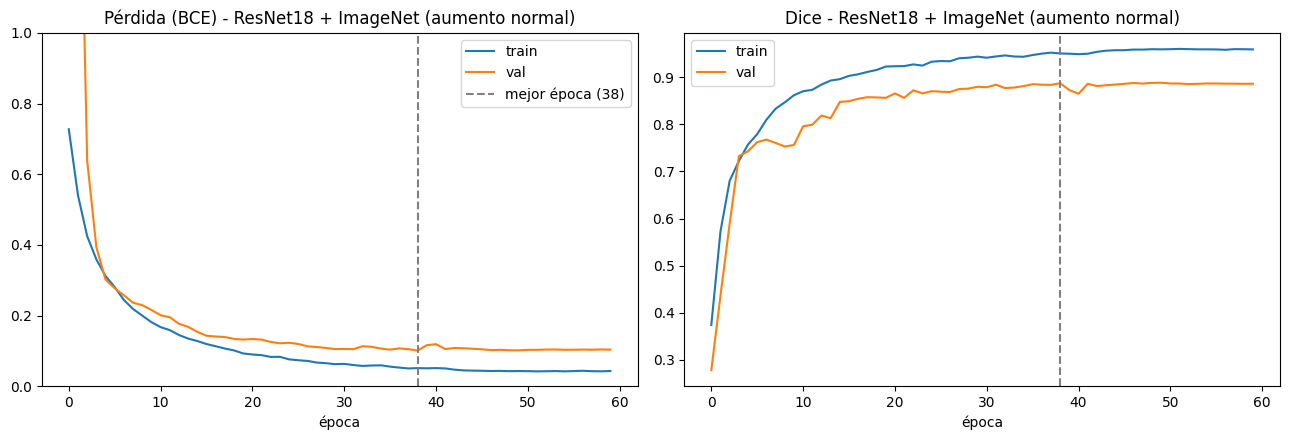

Cargado el modelo de la época 38 (val loss 0.1011)


In [ ]:
#Celda 19: entrenar la línea base (aumento normal)
AUG_FUERTE = False
loaders = {p: get_loader(p) for p in ['train', 'val', 'test']}

trainer_pre = Trainer(encoder_weights='imagenet', nombre='imagenet', num_epochs=60)
trainer_pre.start()
graficar(trainer_pre, 'ResNet18 + ImageNet (aumento normal)')
cargar_mejor(trainer_pre)

**Análisis de las curvas (línea base: ImageNet, aumento normal).** *¿Converge?* Sí: la pérdida de val baja de 0.64 (época 2) a ≈0.10 y el Dice de val supera 0.8 en la época 12 y 0.85 en la 16; después se estabiliza entre 0.86 y 0.89. El mejor modelo (menor pérdida de val, como en el blog) es el de la **época 38** (val loss 0.1011); el Dice de val más alto (0.888) apareció en la 49, pero se elige por pérdida. *¿Sobreajuste?* Leve: train sigue mejorando (Dice 0.870 → 0.923 → 0.959 en las épocas 10, 20 y 59; pérdida 0.167 → 0.090 → 0.043) mientras val se estanca desde la época ≈30 (pérdida ≈0.10–0.13, Dice 0.87–0.89) y la brecha de Dice sube de ≈0.06 (época 20) a ≈0.07 (últimas 10 épocas). La pérdida de val no sube de forma sostenida, solo se aplana, así que no hay un punto de quiebre claro. Dos observaciones: la pérdida de val de la época 0 es 19.7 (pico inicial, probablemente por las estadísticas de BatchNorm del encoder preentrenado en modo evaluación; con pesos aleatorios, en el Paso 8, no ocurre), y el lr baja varias veces por `ReduceLROnPlateau` hasta ≈5e-9, por lo que las últimas épocas casi no cambian. Con 12 fotos de val, diferencias pequeñas entre épocas son ruido.

Época 00 | train loss 0.7395 dice 0.3551 | val loss 19.1675 dice 0.2785 | lr 5.0e-04  <- mejor, guardado
Época 01 | train loss 0.5509 dice 0.5441 | val loss 0.6719 dice 0.4785 | lr 5.0e-04  <- mejor, guardado
Época 02 | train loss 0.4616 dice 0.6257 | val loss 0.9804 dice 0.5648 | lr 5.0e-04
Época 03 | train loss 0.3804 dice 0.6939 | val loss 0.4005 dice 0.6971 | lr 5.0e-04  <- mejor, guardado
Época 04 | train loss 0.3355 dice 0.7103 | val loss 0.3471 dice 0.6956 | lr 5.0e-04  <- mejor, guardado
Época 05 | train loss 0.3056 dice 0.7277 | val loss 0.3109 dice 0.7181 | lr 5.0e-04  <- mejor, guardado
Época 06 | train loss 0.2842 dice 0.7413 | val loss 0.2720 dice 0.6871 | lr 5.0e-04  <- mejor, guardado
Época 07 | train loss 0.2625 dice 0.7574 | val loss 0.2488 dice 0.7534 | lr 5.0e-04  <- mejor, guardado
Época 08 | train loss 0.2412 dice 0.7743 | val loss 0.2306 dice 0.7604 | lr 5.0e-04  <- mejor, guardado
Época 09 | train loss 0.2282 dice 0.7916 | val loss 0.2230 dice 0.7808 | lr 5.0e-04

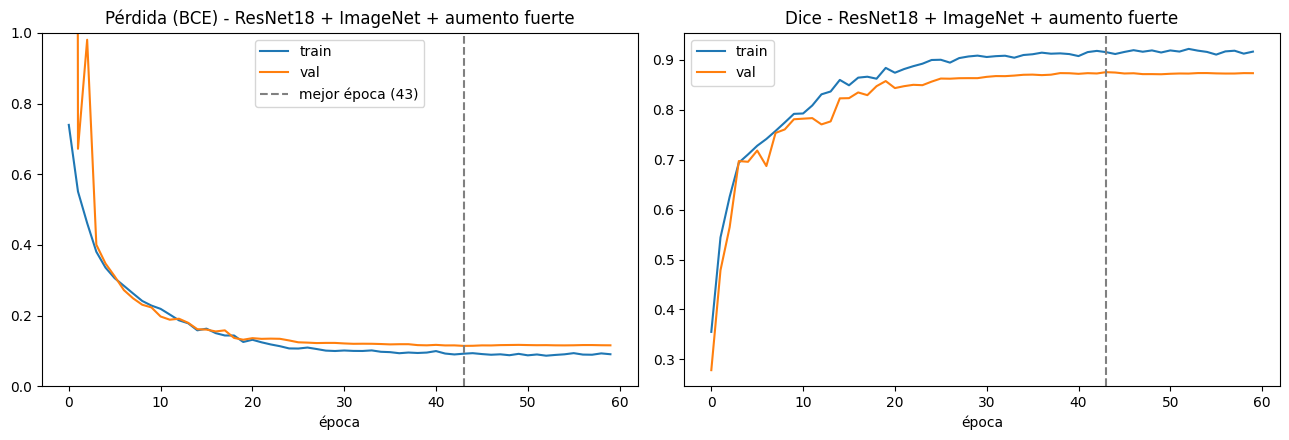

Cargado el modelo de la época 43 (val loss 0.1142)


In [ ]:
#Celda 19b: reentrenar con aumento fuerte
AUG_FUERTE = True
loaders = {p: get_loader(p) for p in ['train', 'val', 'test']}

trainer_aug = Trainer(encoder_weights='imagenet', nombre='imagenet_augfuerte', num_epochs=60)
trainer_aug.start()
graficar(trainer_aug, 'ResNet18 + ImageNet + aumento fuerte')
cargar_mejor(trainer_aug)

In [ ]:
#Celda 19c: comparar con la línea base
def resumen(tr, nombre):
    h = pd.DataFrame(tr.hist)
    b = h.loc[tr.best_epoch]
    ult = h.tail(10)
    return {'modelo': nombre,
            'mejor época': tr.best_epoch,
            'val loss (mejor)': round(b['val_loss'], 4),
            'val dice (mejor)': round(b['val_dice'], 4),
            'brecha dice (últ. 10 épocas)': round((ult['train_dice'] - ult['val_dice']).mean(), 4)}

print(pd.DataFrame([resumen(trainer_pre, 'línea base (aug. normal)'),
                    resumen(trainer_aug, 'aumento fuerte')]).to_string(index=False))

                  modelo  mejor época  val loss (mejor)  val dice (mejor)  brecha dice (últ. 10 épocas)
línea base (aug. normal)           38            0.1011            0.8873                        0.0730
          aumento fuerte           43            0.1142            0.8751                        0.0437


**Análisis: aumento fuerte vs línea base.** Para reducir el sobreajuste se probó un aumento más fuerte en train (volteo, `Affine` con zoom 0.8–1.2, desplazamiento de ±10 % y rotación de ±15°, brillo/contraste, tono/saturación y ruido gaussiano), con 60 épocas en ambos modelos para que la comparación sea justa. La brecha de Dice train–val bajó de 0.073 a 0.044 (Dice de train final 0.916 frente a 0.959): el modelo memoriza menos. Pero **val no mejoró**: mejor pérdida de val 0.1142 (época 43) frente a 0.1011 (época 38), y Dice de val 0.8751 frente a 0.8873; además aprende un poco más lento (Dice de val ≥0.8 en la época 14 frente a la 12). Al repetir este mismo entrenamiento (aumento fuerte, 60 épocas, semilla 42) en corridas anteriores obtuvimos mejores pérdidas de val de 0.0976 y 0.1044, así que la variación entre corridas (≈0.02) es del mismo tamaño que la diferencia entre configuraciones: no podemos afirmar que un aumento sea mejor que el otro. **Decisión:** como la validación no favorece al aumento fuerte (menor pérdida y mayor Dice de val con la línea base), el modelo final para los Pasos 7 y 8 es la línea base: ResNet18 + ImageNet con aumento normal, época 38. El aumento fuerte queda como experimento: redujo la brecha train–val pero no mejoró la validación. La elección se hizo con val y no con test.

## Paso 7. Evaluar y probar con fotos nuevas

In [ ]:
#Celda 22: Dice e IoU en test (y val, para comparar)
def iou_score(pred, targ, eps=1e-7):
    inter = (pred * targ).sum()
    union = pred.sum() + targ.sum() - inter
    return ((inter + eps) / (union + eps)).item()

def dice_img(pred, targ, eps=1e-7):
    return ((2 * (pred * targ).sum() + eps) / (pred.sum() + targ.sum() + eps)).item()

@torch.no_grad()
def evaluar(net, phase):
    net.eval()
    ds = PersonasDataset(df, phase)
    filas, preds = [], []
    for i in range(len(ds)):
        img, msk = ds[i]
        pred = (net(img.unsqueeze(0).to(device)) > 0).float().cpu()[0]   # [1,H,W]
        filas.append({'img': ds.names[i],
                      'dice': dice_img(pred, msk),
                      'iou': iou_score(pred, msk),
                      'pct_real': msk.mean().item() * 100})
        preds.append(pred)
    return pd.DataFrame(filas), preds

# Modelo final: ResNet18 + ImageNet con aumento normal (línea base), elegido por menor pérdida de validación.
# Se cargan los pesos guardados en Drive (no se reentrena).
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
net = smp.Unet("resnet18", encoder_weights=None, classes=1, activation=None).to(device)
ck = torch.load(OUT / 'unet_resnet18_imagenet.pth', map_location=device)
net.load_state_dict(ck['state_dict'])
print(f"Modelo final cargado: época {ck['epoch']} (val loss {ck['val_loss']:.4f})\n")
res_test, preds_test = evaluar(net, 'test')
res_val, _ = evaluar(net, 'val')

print(res_test.round(4).to_string(index=False))
print(f"\nTEST -> Dice: {res_test['dice'].mean():.4f} | IoU: {res_test['iou'].mean():.4f}")
print(f"VAL  -> Dice: {res_val['dice'].mean():.4f} | IoU: {res_val['iou'].mean():.4f}")

Modelo final cargado: época 38 (val loss 0.1011)

                                    img   dice    iou  pct_real
                    IMG_20261013_171458 0.8326 0.7132   12.6038
                        20261014_162602 0.9229 0.8569   13.5620
                        20261015_140419 0.8482 0.7364   13.9587
                    IMG_20261013_172305 0.7605 0.6135   12.4939
                        20261015_133430 0.9393 0.8855   15.9973
                    IMG_20261013_170707 0.8570 0.7498    6.7017
                        20261015_124619 0.8832 0.7909   16.4062
WhatsApp Image 2026-10-14 at 8.12.52 PM 0.9070 0.8299   14.7461
                        20261014_164551 0.9292 0.8677   14.7217
                        20261015_124852 0.9227 0.8565   21.0693
  WhatsApp Image 2026-10-13 at 22.14.34 0.7040 0.5432    6.6772
                    IMG_20261013_174631 0.9573 0.9181   14.6606

TEST -> Dice: 0.8720 | IoU: 0.7801
VAL  -> Dice: 0.8912 | IoU: 0.8085


**Análisis de las métricas.** El modelo final (ResNet18 + ImageNet, aumento normal, época 38) obtiene en test **Dice 0.8720 e IoU 0.7801**, y en val Dice 0.8912 e IoU 0.8085. La diferencia entre val y test es de solo 0.019 de Dice, así que el resultado de validación no estaba muy inflado. Es algo optimista porque el checkpoint se eligió mirando val, y test son solo 12 fotos. Por foto, el Dice de test va de 0.704 a 0.957 (mediana 0.895): diez de las doce fotos están por encima de 0.83 y solo dos por debajo de 0.77, y esas dos arrastran el promedio. (Por foto, Dice = 2·IoU/(1+IoU), pero los promedios de Dice e IoU no cumplen esa relación.)

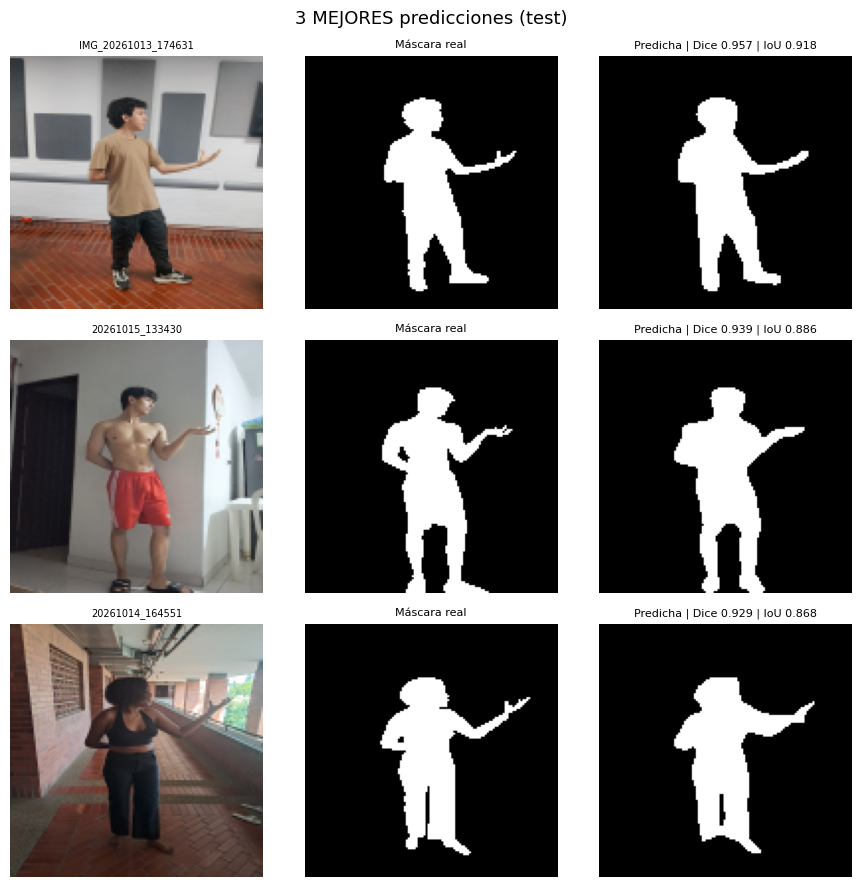

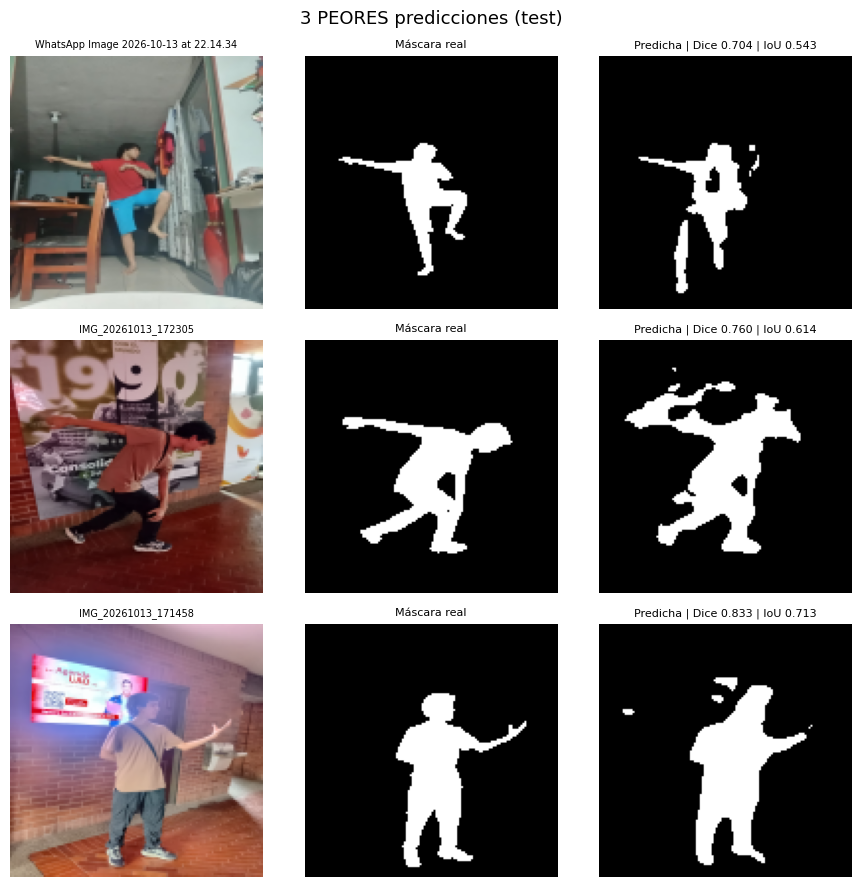

In [ ]:
#Celda 23: 3 mejores y 3 peores predicciones
ds_test = PersonasDataset(df, 'test')
orden = res_test.sort_values('dice', ascending=False)
mejores = list(orden.head(3).index)
peores = list(orden.tail(3).index[::-1])     # la peor primero

def mostrar(indices, titulo):
    fig, ax = plt.subplots(len(indices), 3, figsize=(9, 3 * len(indices)))
    fig.suptitle(titulo, fontsize=13)
    for r, i in enumerate(indices):
        img_t, msk_t = ds_test[i]
        ax[r, 0].imshow(desnormalizar(img_t)); ax[r, 0].set_title(res_test.loc[i, 'img'], fontsize=7)
        ax[r, 1].imshow(msk_t[0], cmap='gray'); ax[r, 1].set_title('Máscara real', fontsize=8)
        ax[r, 2].imshow(preds_test[i][0], cmap='gray')
        ax[r, 2].set_title(f"Predicha | Dice {res_test.loc[i, 'dice']:.3f} | IoU {res_test.loc[i, 'iou']:.3f}", fontsize=8)
        for a in ax[r]: a.axis('off')
    plt.tight_layout(); plt.show()

mostrar(mejores, '3 MEJORES predicciones (test)')
mostrar(peores, '3 PEORES predicciones (test)')

**Análisis de mejores y peores.** *Mejores:* IMG_20261013_174631 (0.957), 20261015_133430 (0.939) y 20261014_164551 (0.929): persona de pie, completa y centrada, con la pose más frecuente del dataset (brazo extendido) y un fondo relativamente simple (pared, pasillo). Los contornos de la predicción son muy parecidos a los de la máscara real. *Peores:* WhatsApp Image 22.14.34 (0.704), IMG_20261013_172305 (0.760) e IMG_20261013_171458 (0.833). En las dos primeras la pose es poco común (pierna levantada en una, cuerpo inclinado en la otra), y la predicción queda fragmentada, con huecos dentro de la persona y con partes de las piernas perdidas o con manchas de más. En las dos últimas el fondo tiene colores y texturas fuertes (un afiche, un letrero), que producen manchas de falsos positivos cerca de la persona. El tamaño del objeto no explica por sí solo los fallos: la foto más pequeña (6.7 %, IMG_20261013_170707) obtuvo 0.857. Con solo tres fotos son hipótesis, no conclusiones.

5 fotos extra
También etiquetadas (debe ser []): []


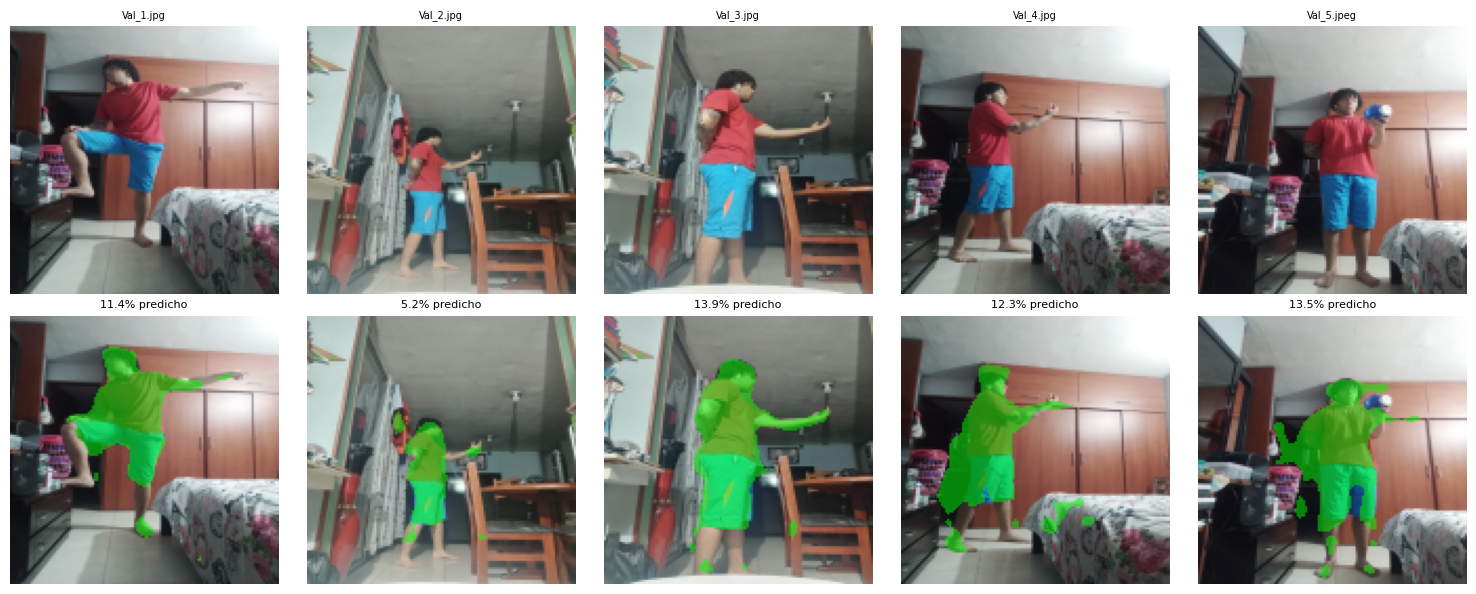

In [ ]:
#Celda 24: fotos extra sin etiquetar
EXTRA = BASE / 'Imagenes_Validacion_Punto1'
archivos_extra = sorted(p for p in EXTRA.glob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
print(len(archivos_extra), "fotos extra")
print("También etiquetadas (debe ser []):", [p.name for p in archivos_extra if p.name in ann])

tf = get_transform('test')       # solo Normalize + ToTensor, sin aumento
net.eval()
n = len(archivos_extra)
fig, ax = plt.subplots(2, n, figsize=(3 * n, 6), squeeze=False)
for j, p in enumerate(archivos_extra):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    x = tf(image=img)['image'].unsqueeze(0).to(device)
    with torch.no_grad():
        pred = (net(x) > 0).float().cpu()[0, 0].numpy()

    overlay = img.astype(np.float32) / 255
    overlay[pred > 0] = 0.5 * overlay[pred > 0] + 0.5 * np.array([0, 1, 0])
    ax[0, j].imshow(img);     ax[0, j].set_title(p.name, fontsize=7); ax[0, j].axis('off')
    ax[1, j].imshow(overlay); ax[1, j].set_title(f"{pred.mean()*100:.1f}% predicho", fontsize=8); ax[1, j].axis('off')
plt.tight_layout(); plt.show()

**Análisis de las 5 fotos nuevas (sin etiquetar).** No hay máscara real, así que la evaluación es solo visual. El modelo encuentra a la persona en las cinco fotos y cubre bien el torso y la camiseta; en Val_1 incluso segmenta la pierna levantada. Los fallos están en los detalles: en Val_2, donde la persona está más lejos (5.2 % predicho), la máscara cubre solo parte del cuerpo; en Val_4 aparecen manchas pequeñas de falso positivo sobre la cama y el piso; y en Val_5 hay una mancha pegada a la mano y al objeto que sostiene. En general funciona algo peor que en los mejores casos de test, pero no se ven errores grandes. Además, las cinco fotos son de la misma persona y el mismo cuarto: son un solo "dominio" y no prueban que el modelo generalice a otras personas o lugares.

## Paso 8. Experimento: ¿importa el pre-entrenamiento?

Se entrena el mismo modelo con `encoder_weights=None` (pesos aleatorios), con el mismo aumento que el modelo final (normal: volteo, rotación y brillo/contraste), la misma semilla, las mismas 60 épocas y los mismos loaders; solo cambia el encoder. La normalización de ImageNet se mantiene para no cambiar otra variable.

In [ ]:
#Celda 25: guardar los resultados del modelo pre-entrenado (modelo final)
net_pre = net
res_test_pre, preds_test_pre = res_test.copy(), preds_test
res_val_pre = res_val.copy()
print("Resultados del modelo pre-entrenado guardados:", len(res_test_pre), "fotos de test y", len(res_val_pre), "de val")

Resultados del modelo pre-entrenado guardados: 12 fotos de test y 12 de val


In [ ]:
#Celda 26: entrenar con pesos aleatorios (mismo aumento normal que el modelo final)
AUG_FUERTE = False
loaders = {p: get_loader(p) for p in ['train', 'val', 'test']}

trainer_rand = Trainer(encoder_weights=None, nombre='sin_preentrenamiento_augnormal', num_epochs=60)
trainer_rand.start()

Época 00 | train loss 0.7269 dice 0.3840 | val loss 2.5488 dice 0.3888 | lr 5.0e-04  <- mejor, guardado
Época 01 | train loss 0.5461 dice 0.5604 | val loss 6.3212 dice 0.3804 | lr 5.0e-04
Época 02 | train loss 0.4690 dice 0.6232 | val loss 0.7236 dice 0.4778 | lr 5.0e-04  <- mejor, guardado
Época 03 | train loss 0.3997 dice 0.6709 | val loss 0.6408 dice 0.5697 | lr 5.0e-04  <- mejor, guardado
Época 04 | train loss 0.3548 dice 0.6892 | val loss 0.5453 dice 0.6044 | lr 5.0e-04  <- mejor, guardado
Época 05 | train loss 0.3186 dice 0.7088 | val loss 0.3964 dice 0.5965 | lr 5.0e-04  <- mejor, guardado
Época 06 | train loss 0.2901 dice 0.7281 | val loss 0.3511 dice 0.6596 | lr 5.0e-04  <- mejor, guardado
Época 07 | train loss 0.2608 dice 0.7692 | val loss 0.3238 dice 0.6080 | lr 5.0e-04  <- mejor, guardado
Época 08 | train loss 0.2558 dice 0.7499 | val loss 0.2987 dice 0.6739 | lr 5.0e-04  <- mejor, guardado
Época 09 | train loss 0.2343 dice 0.7769 | val loss 0.2943 dice 0.6499 | lr 5.0e-04 

Cargado el modelo de la época 27 (val loss 0.2367)


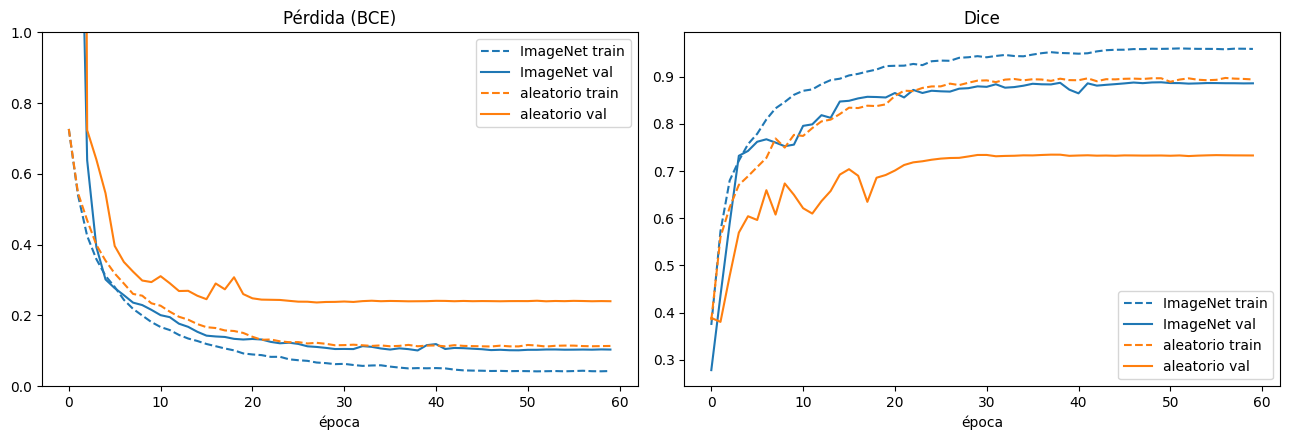

In [ ]:
#Celda 27: recargar el mejor y comparar curvas
ckpt = torch.load(trainer_rand.ckpt_path, map_location=device)
trainer_rand.net.load_state_dict(ckpt['state_dict'])
print(f"Cargado el modelo de la época {ckpt['epoch']} (val loss {ckpt['val_loss']:.4f})")

h1 = pd.read_csv(OUT / 'historial_imagenet.csv')    # historial del modelo ImageNet (línea base) guardado en Drive
h2 = pd.DataFrame(trainer_rand.hist)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(h1['epoch'], h1['train_loss'], 'C0--', label='ImageNet train')
ax[0].plot(h1['epoch'], h1['val_loss'],   'C0',   label='ImageNet val')
ax[0].plot(h2['epoch'], h2['train_loss'], 'C1--', label='aleatorio train')
ax[0].plot(h2['epoch'], h2['val_loss'],   'C1',   label='aleatorio val')
ax[0].set_ylim(0, 1.0); ax[0].set_title('Pérdida (BCE)'); ax[0].set_xlabel('época'); ax[0].legend()
ax[1].plot(h1['epoch'], h1['train_dice'], 'C0--', label='ImageNet train')
ax[1].plot(h1['epoch'], h1['val_dice'],   'C0',   label='ImageNet val')
ax[1].plot(h2['epoch'], h2['train_dice'], 'C1--', label='aleatorio train')
ax[1].plot(h2['epoch'], h2['val_dice'],   'C1',   label='aleatorio val')
ax[1].set_title('Dice'); ax[1].set_xlabel('época'); ax[1].legend()
plt.tight_layout(); plt.show()

**Análisis de las curvas.** Los dos modelos se entrenaron con el mismo aumento (normal), la misma semilla y las mismas 60 épocas; solo cambia el encoder. Con ImageNet el Dice de val supera 0.8 en la época 12 y 0.85 en la 16, y se estabiliza en ≈0.89; la pérdida de val llega a ≈0.10. Con pesos aleatorios el Dice de val sube más lento, se estanca en ≈0.73 y la pérdida de val queda en ≈0.24 (mejor época: 27, val loss 0.2367). La brecha train–val también es mayor: ≈0.89 en train frente a ≈0.73 en val (≈0.16) con pesos aleatorios, contra ≈0.96 y ≈0.89 (≈0.07) con ImageNet. Es decir, el modelo aleatorio sobreajusta más y generaliza peor. Un detalle: el pico de pérdida de val de la época 0 (≈19.7) solo aparece con ImageNet; con pesos aleatorios la pérdida empieza en ≈0.7, lo que apoya la hipótesis de que se debe a las estadísticas de BatchNorm del encoder preentrenado.

   modelo  test Dice  test IoU  val Dice
 ImageNet     0.8720    0.7801    0.8912
Aleatorio     0.7563    0.6196    0.7322


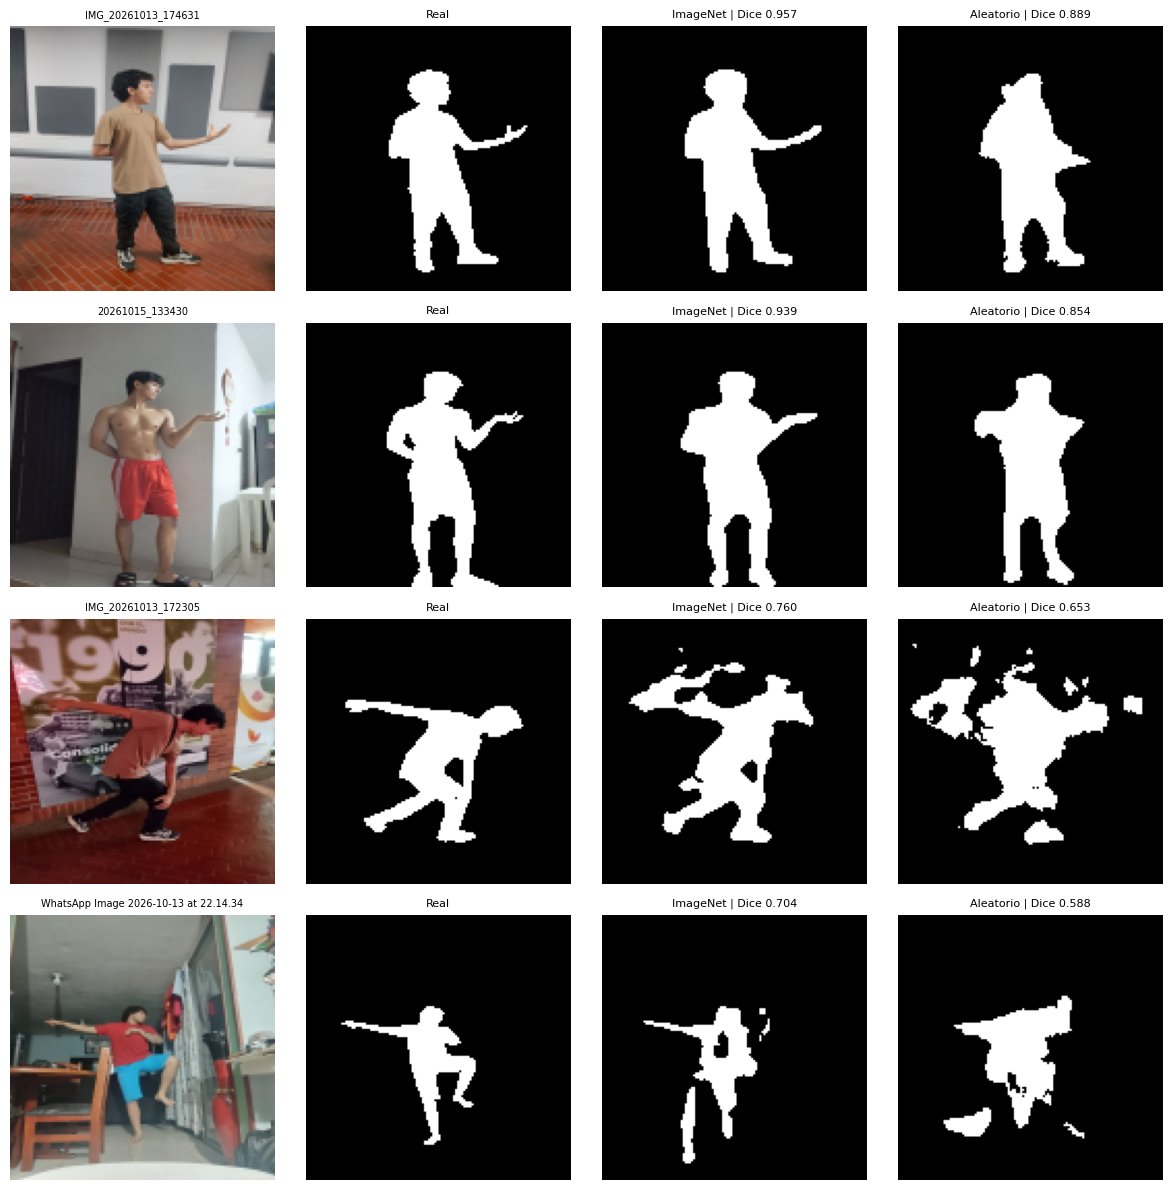

In [ ]:
#Celda 28: Dice e IoU en test y ejemplos lado a lado
res_test_rand, preds_test_rand = evaluar(trainer_rand.net, 'test')
res_val_rand, _ = evaluar(trainer_rand.net, 'val')

tabla = pd.DataFrame({
    'modelo': ['ImageNet', 'Aleatorio'],
    'test Dice': [res_test_pre['dice'].mean(), res_test_rand['dice'].mean()],
    'test IoU':  [res_test_pre['iou'].mean(),  res_test_rand['iou'].mean()],
    'val Dice':  [res_val_pre['dice'].mean(),  res_val_rand['dice'].mean()],
}).round(4)
print(tabla.to_string(index=False))

# Ejemplos: 2 mejores y 2 peores del modelo ImageNet, comparados con el aleatorio
orden = res_test_pre.sort_values('dice', ascending=False)
idxs = list(orden.head(2).index) + list(orden.tail(2).index)

fig, ax = plt.subplots(len(idxs), 4, figsize=(12, 3 * len(idxs)))
for r, i in enumerate(idxs):
    img_t, msk_t = ds_test[i]
    ax[r, 0].imshow(desnormalizar(img_t)); ax[r, 0].set_title(res_test_pre.loc[i, 'img'], fontsize=7)
    ax[r, 1].imshow(msk_t[0], cmap='gray'); ax[r, 1].set_title('Real', fontsize=8)
    ax[r, 2].imshow(preds_test_pre[i][0], cmap='gray')
    ax[r, 2].set_title(f"ImageNet | Dice {res_test_pre.loc[i, 'dice']:.3f}", fontsize=8)
    ax[r, 3].imshow(preds_test_rand[i][0], cmap='gray')
    ax[r, 3].set_title(f"Aleatorio | Dice {res_test_rand.loc[i, 'dice']:.3f}", fontsize=8)
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.show()

**Análisis en test y ejemplos.** En test, el modelo con ImageNet obtiene Dice 0.8720 e IoU 0.7801 (val 0.8912); el modelo con pesos aleatorios obtiene Dice [DICE TEST ALEATORIO] e IoU 0.6198 (val 0.7322). Con ImageNet es mejor en todas las métricas. En los ejemplos, ImageNet gana en las cuatro fotos: 0.957 contra 0.889, 0.939 contra 0.854, 0.760 contra 0.653 y 0.704 contra 0.588. Con pesos aleatorios las siluetas son más burdas, con brazos y piernas menos definidos, y en las fotos difíciles aparecen manchas grandes de falsos positivos.

**Explicación según el tamaño del dataset:** el encoder ResNet18 tiene ≈11 millones de parámetros. Con ImageNet llega con filtros de bordes, texturas y formas aprendidos con más de un millón de imágenes y solo debe adaptarse a "persona". Con pesos aleatorios debe aprender todo eso desde cero con 56 fotos, y esa cantidad no alcanza: por eso generaliza peor y sobreajusta más. Con un dataset mucho más grande la diferencia sería menor. *Limitaciones:* una sola ejecución por modelo, 12 fotos de test y 60 épocas.

## Análisis final del Punto 1

**¿En qué tipo de fotos falla el modelo y por qué?** Falla sobre todo en poses poco frecuentes (pierna levantada, cuerpo inclinado), porque el dataset tiene pocos ejemplos de ellas: la predicción queda fragmentada, con huecos y partes de las piernas perdidas. También falla en fondos con colores y texturas fuertes (afiches, letreros, camas), que producen manchas de falsos positivos, y en las partes delgadas (brazos extendidos, piernas y pies), donde la máscara sale incompleta o irregular. En las fotos nuevas del mismo cuarto el desempeño es algo peor que en los mejores casos de test, aunque sin errores grandes.

**Limitaciones del enfoque:**
- **Cantidad de fotos:** 80 en total (56 para entrenar). Val y test son 12 fotos cada una, así que las métricas son ruidosas (el Dice por foto en test va de 0.70 a 0.96) y una sola ejecución por modelo no permite afirmar diferencias pequeñas.
- **Partición por foto, no por persona o lugar:** es probable que la misma persona o el mismo lugar aparezca en train y en test, lo que hace la estimación algo optimista. Las 5 fotos nuevas son de una sola persona y un solo cuarto.
- **Calidad de las etiquetas:** los polígonos están hechos a mano y son aproximados, sobre todo en cabello y manos; ese error de etiquetado limita el Dice máximo posible.
- **Resolución:** 128×128 con fotos verticales deformadas a cuadrado; las partes finas ocupan pocos píxeles y se pierden.
- **Reproducibilidad y selección:** el entrenamiento no es idéntico entre ejecuciones (la pérdida de val del mismo experimento con aumento fuerte varió entre 0.0976 y 0.1142) y el checkpoint se eligió con val, por lo que val es optimista. El aumento fuerte no mejoró la validación frente a la línea base, así que el modelo final es la línea base.

**Mejoras posibles:** más fotos de más personas y lugares; partición por escena o persona; 256×256 o conservar la proporción con relleno en vez de deformar; etiquetas más finas; probar una pérdida BCE + Dice; y repetir el entrenamiento con varias semillas para reportar media y desviación.

### Pesos entrenados y reproducción de las figuras sin reentrenar (Punto 1)

Los pesos de la U-Net están en Drive (ver tabla de enlaces al inicio del notebook). La siguiente celda lista los archivos guardados, carga los pesos y recalcula el Dice y el IoU en test usando la misma partición (`splits.csv`), sin entrenar nada. Requiere haber ejecutado antes la configuración (Celdas 1 y 2), el redimensionado y la definición del Dataset del Paso 4, y la celda de transformaciones.

In [ ]:
#Reproducir los resultados del Punto 1 SIN reentrenar: carga los pesos guardados en Drive
print("Pesos y particiones guardados en Drive:")
for f in sorted(OUT.glob('*.pth')) + [OUT / 'splits.csv']:
    print(f"  {f.name:45s} {f.stat().st_size/1e6:7.1f} MB")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
df_split = pd.read_csv(OUT / 'splits.csv')     # misma partición que en el entrenamiento

def cargar_unet(nombre_archivo):
    m = smp.Unet("resnet18", encoder_weights=None, classes=1, activation=None).to(device)
    ck = torch.load(OUT / nombre_archivo, map_location=device)
    m.load_state_dict(ck['state_dict'])
    print(f"{nombre_archivo}: mejor época {ck['epoch']} (val loss {ck['val_loss']:.4f})")
    return m.eval()

@torch.no_grad()
def dice_iou_test(m):
    ds = PersonasDataset(df_split, 'test')
    d, i = [], []
    for k in range(len(ds)):
        img, msk = ds[k]
        pred = (m(img.unsqueeze(0).to(device)) > 0).float().cpu()[0]
        inter = (pred * msk).sum()
        d.append(((2 * inter + 1e-7) / (pred.sum() + msk.sum() + 1e-7)).item())
        i.append(((inter + 1e-7) / (pred.sum() + msk.sum() - inter + 1e-7)).item())
    return np.mean(d), np.mean(i)

filas = []
for nombre, archivo in [('ImageNet + aumento normal (modelo final)', 'unet_resnet18_imagenet.pth'),
                        ('ImageNet + aumento fuerte (experimento Paso 6)', 'unet_resnet18_imagenet_augfuerte.pth'),
                        ('Pesos aleatorios + aumento normal (Paso 8)', 'unet_resnet18_sin_preentrenamiento_augnormal.pth')]:
    dice, iou = dice_iou_test(cargar_unet(archivo))
    filas.append({'modelo': nombre, 'test Dice': round(dice, 4), 'test IoU': round(iou, 4)})
print()
print(pd.DataFrame(filas).to_string(index=False))